# Bonus — Búsqueda alta contra oferta baja

**Cliente:** EcoFood
**Qué pide el caso:**

> ¿Dónde hay alta búsqueda (punto 2) pero baja oferta instalada (punto 1)? Ese cruce suele señalar la oportunidad de negocio más concreta de todo el análisis.
> ¿Qué zonas de Buenos Aires presentan mayor oportunidad comercial combinando ambos factores?

Son dos preguntas distintas y se contestan por separado:

1. **¿Qué concepto?** Se cruza la búsqueda (Google Trends) con la oferta de cada concepto (registro del GCBA y Guía Óleo).
2. **¿Qué zonas?** Google Trends no baja a barrio, así que la demanda por zona necesita un supuesto explícito. Se declara y se discute.

## Fuentes

| Archivo | Qué aporta | Punto |
|---|---|---|
| `data/raw/trends_juntos.csv` | Búsqueda de 5 conceptos, Argentina, 5 años | 2 |
| `data/raw/trends_control_caba.csv` | Control con palabras cotidianas, solo CABA, 5 años | bonus |
| `data/processed/establecimientos_clean.csv` | Oferta registrada por el GCBA (Ente de Turismo) | 1 |
| `data/raw/guiaoleo_restaurantes.jsonl` | Oferta de Guía Óleo (2.318 locales) | 3 |
| `data/processed/resenas_clean.csv` | Precio por persona declarado en reseñas | 3 |
| `data/raw/poblacion_por_barrio.csv`, `barrios_caba.geojson` | Población (Censo 2010), barrios y comunas | 1 |

In [1]:
import json
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

RAW = Path('../data/raw')
PROC = Path('../data/processed')
IMG = Path('../images')

# Paleta: una serie en foco (azul) y el resto como contexto (gris). Texto en tinta, nunca en el color de la serie.
SUPERFICIE, TINTA, TINTA_2, TENUE, GRILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e6e5e0'
FOCO, CONTEXTO = '#2a78d6', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': SUPERFICIE, 'axes.facecolor': SUPERFICIE, 'savefig.facecolor': SUPERFICIE,
    'axes.edgecolor': GRILLA, 'axes.labelcolor': TINTA_2, 'xtick.color': TENUE, 'ytick.color': TENUE,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})

ZONA = {1: 'Centro', 3: 'Centro', 2: 'Norte', 12: 'Norte', 13: 'Norte', 14: 'Norte',
        6: 'Oeste', 7: 'Oeste', 11: 'Oeste', 15: 'Oeste',
        4: 'Sur', 5: 'Sur', 8: 'Sur', 9: 'Sur', 10: 'Sur'}


def normalizar(t):
    s = unicodedata.normalize('NFKD', str(t)).encode('ascii', 'ignore').decode()
    return re.sub(r'\s+', ' ', s.lower()).strip()


def clave(t):
    return re.sub(r'[^a-z0-9]', '', normalizar(t))

## 1. La búsqueda: qué crece y qué no

### La serie del punto 2

`trends_juntos.csv` se guardó sin la columna de fechas (`to_csv(index=False)`). Las fechas se pueden reconstruir: el notebook del punto 2 muestra que la serie arranca el 7 de noviembre de 2021 y es semanal. Antes de usarla se verifica que las primeras filas coincidan con lo que ese notebook imprimió.

In [2]:
trends_p2 = pd.read_csv(RAW / 'trends_juntos.csv')
# Primeras filas que muestra google_trends_ecofood_eda.ipynb (2021-11-07, 11-14, 11-21, 11-28)
esperado = [[9, 5, 50, 0, 3], [9, 3, 50, 0, 2], [8, 3, 50, 0, 3], [5, 2, 46, 0, 2]]
assert trends_p2.head(4).values.tolist() == esperado, 'las filas no coinciden: no se puede reconstruir la fecha'
trends_p2.index = pd.date_range('2021-11-07', periods=len(trends_p2), freq='7D', name='fecha')
print('serie del punto 2:', trends_p2.index.min().date(), '->', trends_p2.index.max().date(), f'({len(trends_p2)} semanas)')
print()
print('interés medio por año (años completos), escala común, Argentina:')
anual_p2 = trends_p2[trends_p2.index.year.isin(range(2022, 2026))].groupby(lambda d: d.year).mean().round(1)
anual_p2

serie del punto 2: 2021-11-07 -> 2026-11-01 (261 semanas)

interés medio por año (años completos), escala común, Argentina:


,alimentación saludable,veganismo,sin TACC,café de especialidad,alimentos naturales
fecha,,,,,
2022,5.4,2.0,64.2,0.1,2.2
2023,4.6,1.4,75.9,0.4,2.1
2024,3.6,0.3,78.1,0.7,1.8
2025,3.2,0.1,80.2,1.3,1.7


### Control: ¿"sin TACC" gana por cómo se eligieron las palabras?

La serie del punto 2 compara un rótulo corto y concreto ("sin TACC") con frases que casi nadie escribe tal cual ("alimentación saludable", "veganismo"). La ventaja puede ser un artefacto de esa elección. Para descartarlo se hace **una consulta de control**:

- con las palabras que la gente escribe de verdad: `saludable`, `vegano`, `organico`, `vegetariano`;
- filtrada a **CABA** (`geo='AR-C'`), que es lo que pide el caso, en vez de toda la Argentina.

`pytrends` no es una API oficial y puede fallar sin aviso. Por eso la consulta se guardó apenas llegó y el notebook usa esa captura. Si se pone `ACTUALIZAR_TRENDS = True`, intenta consultar de nuevo y, si falla, sigue con la última captura guardada.

In [3]:
ACTUALIZAR_TRENDS = False   # True para volver a consultar Google Trends
ruta_control = RAW / 'trends_control_caba.csv'
TERMINOS_CONTROL = ['sin tacc', 'saludable', 'vegano', 'organico', 'vegetariano']

if ACTUALIZAR_TRENDS:
    try:
        from pytrends.request import TrendReq
        cliente = TrendReq(hl='es-AR', tz=180)
        cliente.build_payload(TERMINOS_CONTROL, geo='AR-C', timeframe='today 5-y')
        nuevo = cliente.interest_over_time()
        if nuevo.empty:
            raise ValueError('Trends devolvió una tabla vacía')
        nuevo = nuevo[~nuevo['isPartial']].drop(columns='isPartial')
        nuevo.index.name = 'fecha'
        nuevo.to_csv(ruta_control)
        print('consulta nueva guardada en', ruta_control)
    except Exception as exc:  # noqa: BLE001
        print(f'no se pudo consultar Trends ({type(exc).__name__}: {exc}); se usa la última captura guardada')

control = pd.read_csv(ruta_control, parse_dates=['fecha'], index_col='fecha')
print('captura de control:', control.index.min().date(), '->', control.index.max().date(), f'({len(control)} semanas), CABA')
print()
print('interés medio en los 5 años, escala común:')
print(control.mean().round(1).sort_values(ascending=False).to_string())
print()
anual_control = control[control.index.year.isin(range(2022, 2026))].groupby(lambda d: d.year).mean().round(1)
anual_control.loc['cambio 2022-2025'] = anual_control.loc[2025] - anual_control.loc[2022]
anual_control

captura de control: 2021-11-14 -> 2026-11-08 (261 semanas), CABA

interés medio en los 5 años, escala común:
sin tacc       65.1
saludable      38.1
vegano         31.1
organico       14.9
vegetariano    11.3



,sin tacc,saludable,vegano,organico,vegetariano
fecha,,,,,
2022,55.2,38.4,44.3,16.8,17.3
2023,65.8,37.1,35.4,16.7,13.2
2024,69.5,34.7,28.0,14.9,9.7
2025,72.4,39.3,22.9,13.3,7.5
cambio 2022-2025,17.2,0.9,-21.4,-3.5,-9.8


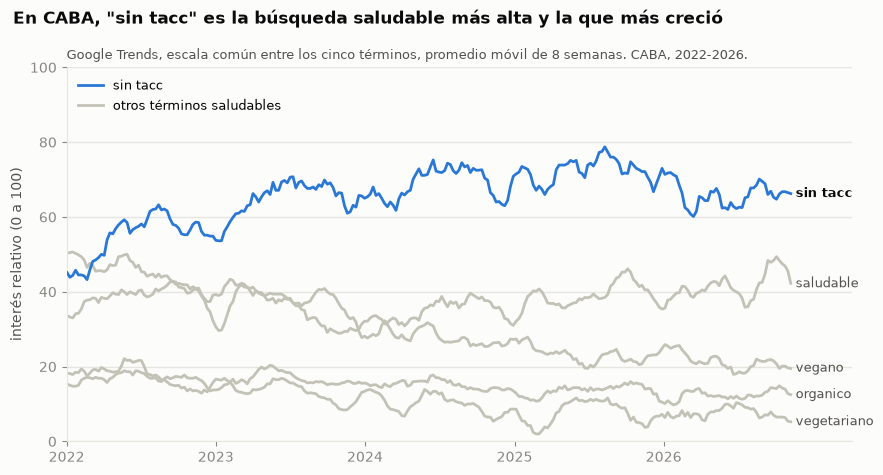

In [4]:
suave = control.rolling(8, min_periods=8).mean().dropna()
orden = suave.iloc[-1].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 4.8))
for termino in orden:
    foco = termino == 'sin tacc'
    ax.plot(suave.index, suave[termino], color=FOCO if foco else CONTEXTO, linewidth=2, zorder=3 if foco else 2)
    ax.text(suave.index[-1] + pd.Timedelta(days=12), suave[termino].iloc[-1], termino,
            va='center', fontsize=9, color=TINTA if foco else TINTA_2, fontweight='bold' if foco else 'normal')
ax.set_ylim(0, 100)
ax.set_xlim(suave.index[0], suave.index[-1] + pd.Timedelta(days=150))
ax.set_xticks(pd.to_datetime([f'{a}-01-01' for a in range(2022, 2027)]))
ax.set_xticklabels([str(a) for a in range(2022, 2027)])
ax.grid(axis='y', color=GRILLA, linewidth=1)
ax.set_axisbelow(True)
ax.set_ylabel('interés relativo (0 a 100)')
ax.legend(handles=[Line2D([], [], color=FOCO, lw=2, label='sin tacc'),
                   Line2D([], [], color=CONTEXTO, lw=2, label='otros términos saludables')],
          loc='upper left', frameon=False, fontsize=9)
fig.suptitle('En CABA, "sin tacc" es la búsqueda saludable más alta y la que más creció',
             x=0.02, ha='left', fontsize=12, color=TINTA, fontweight='bold')
ax.set_title('Google Trends, escala común entre los cinco términos, promedio móvil de 8 semanas. CABA, 2022-2026.',
             loc='left', fontsize=9, color=TINTA_2)
plt.tight_layout()
plt.savefig(IMG / '08_busqueda_sin_tacc_caba.png', dpi=150, bbox_inches='tight')
plt.show()

**Lectura:** el resultado del punto 2 se sostiene, pero más chico.

- En la serie del punto 2 (Argentina, frases poco buscadas), "sin TACC" le saca casi 20 veces a "alimentación saludable". Esa distancia **era en buena parte un artefacto** de las palabras elegidas.
- En el control (CABA, palabras cotidianas), "sin tacc" sigue primero (65 de media), pero la distancia es de 1,7 veces sobre "saludable" (38) y de 2 veces sobre "vegano" (31).
- Lo que no cambia en ninguna de las dos series es la **dirección**: "sin tacc" es el término que más creció entre 2022 y 2025 (+17 puntos en CABA), "saludable" está plano y "vegano" y "vegetariano" caen a la mitad.

**Explicación alternativa:** "sin TACC" es el rótulo oficial de los envases aptos para celíacos, así que se busca para comprar, no por curiosidad. No se descarta, pero no le resta: para una línea de **productos**, que la gente busque el rótulo del envase es justamente la señal que importa.

## 2. La oferta de cada concepto

Para cada concepto se cuenta la oferta en las dos fuentes:

- **GCBA (punto 1):** por la columna `cocina`. Es una clasificación cerrada: si no hay categoría, la oferta es invisible.
- **Guía Óleo:** locales dentro de CABA cuyo **nombre** dice que son del rubro. Es una cota inferior: un local puede tener opciones sin TACC o veganas sin decirlo en el nombre.

Los nombres que matchean se listan para poder auditarlos.

In [5]:
oferta = pd.read_csv(PROC / 'establecimientos_clean.csv')
geo = json.loads((RAW / 'barrios_caba.geojson').read_text(encoding='utf-8'))
crudo = pd.DataFrame([json.loads(l) for l in (RAW / 'guiaoleo_restaurantes.jsonl').open(encoding='utf-8')])


def anillos(geom):
    return [geom['coordinates'][0]] if geom['type'] == 'Polygon' else [p[0] for p in geom['coordinates']]


def dentro(x, y, anillo):
    adentro, j = False, len(anillo) - 1
    for i in range(len(anillo)):
        (xi, yi), (xj, yj) = anillo[i][:2], anillo[j][:2]
        if ((yi > y) != (yj > y)) and (x < (xj - xi) * (y - yi) / (yj - yi) + xi):
            adentro = not adentro
        j = i
    return adentro


canonico = {clave(b): b for b in oferta['barrio'].unique()}
canonico.update({'boca': 'La Boca', 'paternal': 'La Paternal', 'parquechas': 'Parque Chas'})


def barrio_de(lat, lon):
    for f in geo['features']:
        if any(dentro(lon, lat, a) for a in anillos(f['geometry'])):
            return canonico.get(clave(f['properties']['BARRIO']), f['properties']['BARRIO'])
    return None


crudo['barrio'] = [barrio_de(float(la), float(lo)) for la, lo in zip(crudo['lat'], crudo['lon'])]
go = crudo[crudo['barrio'].notna()].copy()
go['nombre_norm'] = go['nombre'].fillna('').map(normalizar)
print('locales de Guía Óleo dentro de CABA:', len(go))

CONCEPTOS = {
    'sin TACC': {'busqueda': ['sin tacc'], 'cocina_gcba': [], 'nombre': r'gluten|tacc|celiac|celimuzza'},
    'vegano / vegetariano': {'busqueda': ['vegano', 'vegetariano'], 'cocina_gcba': ['VEGETARIANA'],
                             'nombre': r'vegan|veggie|vegetarian|plant.?based'},
    'saludable / natural / orgánico': {'busqueda': ['saludable', 'organico'], 'cocina_gcba': ['NATURISTA'],
                                       'nombre': r'natural|saludable|healthy|organic|organico'},
}

filas = []
for concepto, d in CONCEPTOS.items():
    en_nombre = go['nombre_norm'].str.contains(d['nombre'], regex=True)
    go['es_' + clave(concepto)] = en_nombre
    print(f'\n{concepto} -> nombres en Guía Óleo ({int(en_nombre.sum())}):', sorted(go.loc[en_nombre, 'nombre'].unique()))
    filas.append({
        'concepto': concepto,
        'busqueda_CABA_media': control[d['busqueda']].mean().sum().round(1),
        'cambio_2022_2025': anual_control.loc['cambio 2022-2025', d['busqueda']].sum().round(1),
        'oferta_GCBA': int(oferta['cocina'].isin(d['cocina_gcba']).sum()) if d['cocina_gcba'] else 'sin categoría',
        'oferta_GuiaOleo': int(en_nombre.sum()),
        'oferta_GuiaOleo_pct': round(en_nombre.mean() * 100, 2),
    })
cruce = pd.DataFrame(filas).set_index('concepto')
cruce

locales de Guía Óleo dentro de CABA: 2235

sin TACC -> nombres en Guía Óleo (13): ['Anatani Yummy & Gluten Free', 'Bäcke Gluten Free', 'CeliMuzza Sucursal Villa Ortuzar (ex ZeroGluten)', 'Gluten Free Point', 'La Union Gluten Free Beruti', 'La Unión Gluten Free Bakery', "Ma m'ere TETE' Sans Gluten.", 'Pain Du Jour - Gluten Free', 'Pain Du Jour - gluten free', 'Senza Tacc', 'Verde Pistacho- vegan & gluten free']

vegano / vegetariano -> nombres en Guía Óleo (4): ['Almacén de la plaza Vegan', 'Gordo Vegano', 'Pizza Vegana Villa Devoto', 'Verde Pistacho- vegan & gluten free']

saludable / natural / orgánico -> nombres en Guía Óleo (2): ['Infinita Caballito • Pastelería Saludable', 'Lo Simple Mercado Natural']


,busqueda_CABA_media,cambio_2022_2025,oferta_GCBA,oferta_GuiaOleo,oferta_GuiaOleo_pct
concepto,,,,,
sin TACC,65.1,17.2,sin categoría,13,0.58
vegano / vegetariano,42.4,-31.2,4,4,0.18
saludable / natural / orgánico,53.0,-2.6,7,2,0.09


**Lectura (primera pregunta del bonus):** el concepto con **alta búsqueda y baja oferta** es **sin TACC**.

| Concepto | Búsqueda en CABA | Tendencia 2022-2025 | Oferta especializada |
|---|---|---|---|
| sin TACC | la más alta (65) | crece (+17) | 13 locales en Guía Óleo (0,6%); el GCBA no tiene la categoría |
| vegano / vegetariano | 42 (sumando dos términos) | cae (−31) | 4 en el GCBA, 4 en Guía Óleo |
| saludable / orgánico | 53 (sumando dos términos) | plana (−3) | 7 en el GCBA, 2 en Guía Óleo |

Sumar dos términos agranda a los competidores, así que la comparación es conservadora: "sin tacc" gana con un solo término.

Lo vegano tiene la oferta más chica, pero su búsqueda cae a la mitad: es un nicho que se achica, no una oportunidad que crece.

**Lo que esta tabla no mide:** la oferta sale de dos fuentes de **gastronomía**. Una línea de productos compite también en supermercados y dietéticas, que no están en ningún dataset del trabajo. Que haya pocos locales sin TACC no dice cuántos productos sin TACC hay en góndola. Es la limitación principal del bonus.

## 3. ¿En qué zonas?

### El supuesto que hace falta (y por qué es razonable acá)

Google Trends no baja a barrio: CABA es la unidad más chica. Para repartir la demanda por zona hace falta un supuesto, y se declara:

> **La necesidad de productos sin TACC se reparte según la población.**

Para la mayoría de los conceptos sería un supuesto flojo, porque "comer saludable" depende del estilo de vida y del ingreso. La celiaquía es distinta: es una **condición médica**, no una preferencia. Que haya un celíaco en la familia no depende del barrio. Lo que sí depende del barrio es **cuánto se puede pagar**, y eso se mira aparte con el precio declarado en las reseñas.

### El indicador

**Habitantes por local sin TACC especializado**: cuánta gente hay en la zona por cada local que se especializa. Cuanto más alto, más necesidad sin atender cerca de casa.

**El chequeo que pide el caso:** un barrio con cero oferta sin TACC puede ser simplemente un barrio con poca gastronomía en general. Por eso se informa también cuántos locales tiene en total.

In [6]:
barrios = pd.DataFrame([
    {'barrio': canonico.get(clave(f['properties']['BARRIO']), f['properties']['BARRIO']),
     'comuna': int(float(f['properties']['COMUNA']))}
    for f in geo['features']
]).drop_duplicates('barrio').set_index('barrio')

poblacion = pd.read_csv(RAW / 'poblacion_por_barrio.csv')
poblacion['barrio'] = poblacion['BARRIO'].map(lambda b: canonico.get(clave(b), b))
barrios['poblacion'] = poblacion.set_index('barrio')['POBLACION']
barrios['zona'] = barrios['comuna'].map(ZONA)
barrios['locales_gcba'] = oferta['barrio'].value_counts()
barrios['locales_go'] = go['barrio'].value_counts()
barrios['sin_tacc'] = go.loc[go['es_sintacc'], 'barrio'].value_counts()
barrios[['locales_gcba', 'locales_go', 'sin_tacc']] = barrios[['locales_gcba', 'locales_go', 'sin_tacc']].fillna(0).astype(int)

resenas = pd.read_csv(PROC / 'resenas_clean.csv')
precios = resenas[resenas['precio'] >= 1000]
por_barrio = precios.groupby('barrio')['precio'].agg(['median', 'size'])
barrios['precio_mediano'] = por_barrio['median'].where(por_barrio['size'] >= 5)
barrios['n_precios'] = por_barrio['size'].reindex(barrios.index).fillna(0).astype(int)

assert barrios['poblacion'].notna().all() and len(barrios) == 48
print('barrios:', len(barrios), '| población total (Censo 2010):', int(barrios['poblacion'].sum()))
print('locales sin TACC especializados:', int(barrios['sin_tacc'].sum()), 'en', int((barrios['sin_tacc'] > 0).sum()), 'barrios')

zonas = barrios.groupby('zona').agg(
    poblacion=('poblacion', 'sum'), locales_go=('locales_go', 'sum'), sin_tacc=('sin_tacc', 'sum'))
zonas['hab_por_local_sin_tacc'] = (zonas['poblacion'] / zonas['sin_tacc']).round(-3)
zonas['precio_mediano'] = precios.groupby('zona')['precio'].median()
zonas['n_precios'] = precios.groupby('zona').size()
zonas['barrios_con_sin_tacc'] = barrios[barrios['sin_tacc'] > 0].groupby('zona').apply(lambda d: ', '.join(d.index)).reindex(zonas.index)
zonas.sort_values('hab_por_local_sin_tacc', ascending=False)

barrios: 48 | población total (Censo 2010): 2890151
locales sin TACC especializados: 13 en 9 barrios


,poblacion,locales_go,sin_tacc,hab_por_local_sin_tacc,precio_mediano,n_precios,barrios_con_sin_tacc
zona,,,,,,,
Sur,912306,182,2,456000.0,33000.0,35,Almagro
Centro,393423,412,2,197000.0,25000.0,109,San Nicolás
Oeste,769073,596,4,192000.0,27500.0,98,"Chacarita, Agronomía, Villa Ortúzar, Villa Devoto"
Norte,815349,1045,5,163000.0,30000.0,228,"Palermo, Belgrano, Recoleta"


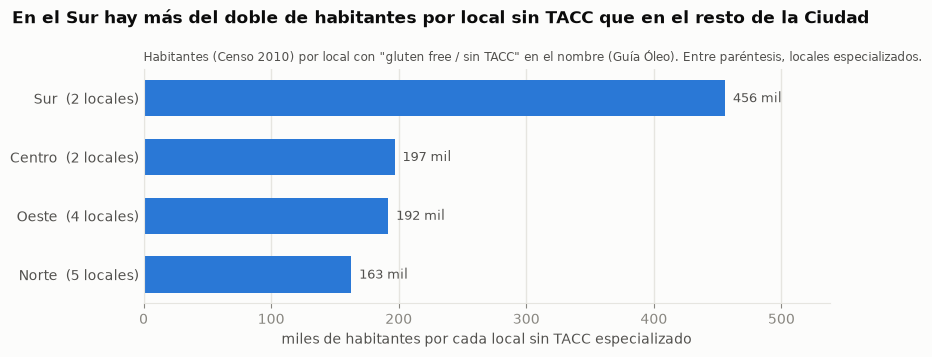

In [7]:
orden = zonas.sort_values('hab_por_local_sin_tacc')
fig, ax = plt.subplots(figsize=(8.5, 3.6))
etiquetas = [f'{z}  ({int(n)} local{"es" if n != 1 else ""})' for z, n in zip(orden.index, orden['sin_tacc'])]
ax.barh(etiquetas, orden['hab_por_local_sin_tacc'] / 1000, color=FOCO, height=0.62)
for i, v in enumerate(orden['hab_por_local_sin_tacc'] / 1000):
    ax.text(v + 6, i, f'{v:,.0f} mil'.replace(',', '.'), va='center', fontsize=9, color=TINTA_2)
ax.set_xlim(0, orden['hab_por_local_sin_tacc'].max() / 1000 * 1.18)
ax.grid(axis='x', color=GRILLA, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(axis='y', length=0, labelcolor=TINTA_2)
ax.set_xlabel('miles de habitantes por cada local sin TACC especializado')
fig.suptitle('En el Sur hay más del doble de habitantes por local sin TACC que en el resto de la Ciudad',
             x=0.02, ha='left', fontsize=12, color=TINTA, fontweight='bold')
ax.set_title('Habitantes (Censo 2010) por local con "gluten free / sin TACC" en el nombre (Guía Óleo). '
             'Entre paréntesis, locales especializados.', loc='left', fontsize=8.5, color=TINTA_2)
plt.tight_layout()
plt.savefig(IMG / '09_habitantes_por_local_sin_tacc.png', dpi=150, bbox_inches='tight')
plt.show()

### Barrios candidatos

Se buscan barrios con **mucha gente** (60.000 habitantes o más), **gastronomía suficiente** (40 locales o más en Guía Óleo, para que el cero no sea "poca oferta en general") y **ningún local sin TACC especializado**.

La columna `p_cero_por_azar` dice qué tan probable es ver cero locales especializados en un barrio con esa cantidad de locales si el rubro se repartiera igual en toda la Ciudad (0,6%). Es el mismo chequeo contra el azar del punto 1.

In [8]:
p_ciudad = barrios['sin_tacc'].sum() / barrios['locales_go'].sum()
barrios['p_cero_por_azar'] = (1 - p_ciudad) ** barrios['locales_go']

candidatos = barrios[(barrios['poblacion'] >= 60_000) & (barrios['locales_go'] >= 40) & (barrios['sin_tacc'] == 0)]
print(f'tasa de locales sin TACC especializados en Guía Óleo: {p_ciudad * 100:.2f}%')
print()
print('candidatos:')
print(candidatos.sort_values('poblacion', ascending=False)[
    ['zona', 'poblacion', 'locales_gcba', 'locales_go', 'sin_tacc', 'p_cero_por_azar', 'precio_mediano', 'n_precios']
].round(3).to_string())
print()
print('descartados por tener poca gastronomía en general (>= 60.000 hab., < 40 locales, 0 sin TACC):')
poca = barrios[(barrios['poblacion'] >= 60_000) & (barrios['locales_go'] < 40) & (barrios['sin_tacc'] == 0)]
print(poca.sort_values('poblacion', ascending=False)[['zona', 'poblacion', 'locales_go']].to_string())
print()
print('precio mediano por persona en toda la Ciudad (reseñas):', int(precios['precio'].median()))

tasa de locales sin TACC especializados en Guía Óleo: 0.58%

candidatos:
                 zona  poblacion  locales_gcba  locales_go  sin_tacc  p_cero_por_azar  precio_mediano  n_precios
barrio                                                                                                          
Caballito       Oeste     176076           124         139         0            0.444         23000.0         25
Balvanera      Centro     138926           212          49         0            0.751         20000.0         11
Villa Urquiza   Norte      91563            27          55         0            0.726         23500.0         11
Villa Crespo    Oeste      81959            44          93         0            0.581         32500.0         26
Retiro         Centro      65413           109          93         0            0.581         25000.0         19

descartados por tener poca gastronomía en general (>= 60.000 hab., < 40 locales, 0 sin TACC):
               zona  poblacion  locales_g

**Lectura (segunda pregunta del bonus):**

- **Por zona, el Sur es el menos atendido:** 456 mil habitantes por local sin TACC especializado, más del doble que el resto (entre 163 y 197 mil). Y los dos locales del Sur están en Almagro: en el resto del Sur (Barracas, La Boca, Parque Patricios, Nueva Pompeya, Villa Lugano, Villa Soldati, Mataderos, entre otros) no hay **ninguno**.
- **Por barrio, el candidato más sólido es Caballito:** 176 mil habitantes, 139 locales en Guía Óleo y ninguno sin TACC especializado. Le siguen Balvanera, Villa Urquiza, Villa Crespo y Retiro, con el mismo perfil y menos población.
- **Flores, Villa Lugano, Barracas y Mataderos quedan afuera** aunque tienen mucha población: tienen tan poca gastronomía en Guía Óleo que su cero no dice nada. Es el chequeo que pide el caso ("¿no es simplemente un barrio con poca oferta gastronómica en general?").

**Lo que hay que decir con honestidad:**

- **Ningún barrio es una brecha contra el azar.** Con 0,6% de locales especializados, ver cero en un barrio de 50 a 140 locales es lo esperable (`p_cero_por_azar` entre 0,44 y 0,75). El hallazgo no es que a un barrio le falte lo que otros tienen: es que **la oferta especializada es mínima en toda la Ciudad** y está más lejos de donde vive más gente.
- **El poder adquisitivo no se puede afirmar.** El proxy del punto 1 le da al Sur el perfil de consumo más bajo. El precio declarado en las reseñas le da la mediana más alta (33 mil), pero son solo 35 precios: casi la mitad de Almagro y el resto de a 1 a 6 por barrio. No alcanza para estimar el poder de compra de la zona. Si el producto es premium, el Sur es la apuesta con más incertidumbre. Caballito tiene un precio algo por debajo de la mediana de la Ciudad (23 mil contra 30 mil), con 25 precios.
- **"Sur" es la agrupación del punto 1** (comunas 4, 5, 8, 9 y 10). Incluye barrios del suroeste como Liniers, Floresta o Villa Luro. Con otra agrupación de zonas, el número cambia; lo que no cambia es que fuera de Almagro no hay ningún local especializado en esas comunas.
- **La gente se mueve.** Los locales especializados son de destino: un celíaco de Caballito puede ir a Almagro o a Palermo. El indicador mide cercanía, no acceso.
- **La población es del Censo 2010** y la oferta especializada se cuenta por el nombre del local, así que es una cota inferior.

## 4. Respuesta al bonus

1. **¿Dónde hay alta búsqueda y baja oferta?** En **sin TACC**. Es la búsqueda saludable más alta de CABA y la que más creció desde 2022, y la oferta especializada es de 13 locales en 2.235 (0,6%); el registro oficial ni siquiera la clasifica. Las reseñas del punto 3 lo confirman desde el consumidor: es el tema saludable más mencionado y aparece con lenguaje de escasez ("de esos pocos refugios", "no se consigue en todos lados").
2. **¿Qué zonas?** Con el supuesto de que la necesidad sigue a la población, el **Sur** es la zona menos atendida (más del doble de habitantes por local especializado que el resto) y **Caballito** es el barrio candidato más sólido para un primer test: mucha gente, gastronomía activa y ninguna oferta especializada.

**Grado de confianza:** el concepto (sin TACC) está respaldado por tres fuentes independientes: búsqueda, reseñas y oferta. Las zonas dependen de un supuesto y de una oferta contada por nombre: son **candidatos para validar**, no una recomendación cerrada.

**Qué haría falta para confirmarlo:** relevar la oferta sin TACC en supermercados y dietéticas de esas zonas, que es la competencia real de un producto, y medir el tamaño de la demanda con una encuesta o con datos de ventas.